# Users, experts, LLMs and an SVM labelling the same mental-health posts

Experiments for a *Matters Arising* on Kallstenius et al. (2025), "Comparing traditional natural language processing and large language models for mental health status classification", *Scientific Reports* 15:24102.

**Claim under test.** The paper ranks a TF-IDF + SVM pipeline (95% accuracy) above a zero-shot LLM (65%) by agreement with the Kaggle *Sentiment Analysis for Mental Health* labels. Those labels are self-reported or source-derived, not clinical. We ask who each method agrees with when the same 103 posts are also rated by human experts.

**Pipeline.** Each step is one section: a description cell, then a code cell. Every step writes its output to `OUT_DIR`, so later steps (and the paid LLM calls) never need to be re-run.

| Step | Purpose | Main output |
|---|---|---|
| 0 | Setup and data | `items.csv` |
| 1 | Expert labels and baseline agreement | `expert_labels.csv`, `agreement_experts.csv` |
| 2 | LLM labelling (gpt-4o-mini, gpt-4.1, Claude's haiku-5.5) | `llm_scores_<model>.csv`, `llm_labels.csv` |
| 3 | SVM replication | `svm_labels.csv`, `svm_heldout.txt` |
| 4 | Head-to-head agreement, confusion matrices, top-k robustness | `agreement_overall.csv`, `fig_agreement.png`, `fig_confusion.png`, `topk_agreement.csv` |
| 4d | Sensitivity: reliability (Krippendorff's α) and three-rater consensus | `reliability_alpha.csv`, `agreement_cons3.csv` |
| 5 | Stratification by text length | `agreement_by_length.csv`, `fig_length.png` |
| 6 | Shortcut check (style-only classifier) | `shortcut.txt`, `style_by_class.csv` |

**Author**: Sergio Rojas-Galeano, Universidad Distrital Francisco José de Caldas.

**email**: `srojas@udistrital.edu.co`.

**Version**: v1.0. Oct/2026.

**License**: MIT

### How to reproduce

**To inspect the results, nothing needs to be run:** every cell's output is saved in this notebook.

**To re-run it:**
1. Download `data/` and `out/` from the [GitHub repository](https://github.com/GITHUB_USER/mental-health-label-agreement), add the Kaggle archive `sentiment-analysis-for-mental-health.zip` to `data/`, copy both folders to your Google Drive, and set `DATA_DIR` and `OUT_DIR` in the first code cell.
2. Run all cells. With `out/` in place the notebook reuses the saved LLM responses and SVM labels: no API calls are made, it takes a few minutes, and every number is reproduced exactly.

**To relabel from scratch:** delete `out/llm_raw_*.jsonl` and `out/svm_labels.csv`, and add `OPENAI_API_KEY` and `ANTHROPIC_API_KEY` to Colab Secrets. The SVM step then takes about 40 minutes; LLM costs are under US$1 per model. Seeds are fixed (`SEED = 42`), but LLM responses may vary slightly between runs even at temperature 0.


## 0. Setup and data

**Inputs.** The Kaggle archive `sentiment-analysis-for-mental-health.zip` (file `Combined Data.csv`; column `Unnamed: 0` is the row id) and the three expert files `ratings_KYG82_….csv`, `ratings_VPR17_….csv`, `ratings_NEL81_….csv`. Located in the shared Drive folder `DATA_DIR`.

**What it does.** Loads everything, checks that the 103 rated statements map onto Kaggle rows through `statement_id`, and builds one master table. The statement text is taken from the original Kaggle file.

**Output.** `items.csv`: `statement_id`, `text`, `user` (Kaggle label), `size` (short / mid / long), `word_count`.

API keys are read from Colab Secrets (`OPENAI_API_KEY`, `CLAUDE_API_KEY`); any experimenter should use their own.

In [ ]:
# ---------- configuration (edit here) ----------
DATA_DIR = '/content/drive/MyDrive/LLM_mental_health/data'   # shared Drive folder with the input files
OUT_DIR  = '/content/drive/MyDrive/LLM_mental_health/out'    # results are saved here
KAGGLE_ZIP = 'sentiment-analysis-for-mental-health.zip'
EXPERT_FILES = {                                             # expert id -> file name
    'KYG82': 'ratings_KYG82_20260221_1959.csv',
    'VPR17': 'ratings_VPR17_20260302_1114.csv',
    'NEL81': 'ratings_NEL81_20260302_2255.csv',
}
PRIMARY_EXPERTS = ['KYG82', 'VPR17']   # consensus benchmark; all three experts are used as a sensitivity check only
SEED = 42
N_BOOT = 2000                          # bootstrap resamples for confidence intervals

import os, sys, re, json, time, zipfile, itertools, warnings
warnings.filterwarnings('ignore')
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    !pip -q install krippendorff openai anthropic

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import krippendorff
from sklearn.metrics import cohen_kappa_score

os.makedirs(OUT_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)
CATS = ['Normal', 'Anxiety', 'Depression', 'Suicidal', 'Stress', 'Bipolar', 'Personality disorder']
SIZES = ['short', 'mid', 'long']
def out(name): return os.path.join(OUT_DIR, name)

# ---------- Kaggle data ----------
with zipfile.ZipFile(os.path.join(DATA_DIR, KAGGLE_ZIP)) as z:
    with z.open('Combined Data.csv') as f:
        kaggle = pd.read_csv(f).rename(columns={'Unnamed: 0': 'row_id'})
kaggle = kaggle.dropna(subset=['statement']).reset_index(drop=True)
print('Kaggle rows (non-empty):', len(kaggle))

# ---------- expert files ----------
experts = {e: pd.read_csv(os.path.join(DATA_DIR, f)).set_index('statement_id') for e, f in EXPERT_FILES.items()}
ids = experts[PRIMARY_EXPERTS[0]].index
assert all(set(d.index) == set(ids) for d in experts.values()), 'expert files rate different statements'

# ---------- master table ----------
base = experts[PRIMARY_EXPERTS[0]]
items = pd.DataFrame({'statement_id': ids, 'user': base.loc[ids, 'user_status'].values,
                      'size': base.loc[ids, 'text_size'].values, 'word_count': base.loc[ids, 'word_count'].values})
items = items.merge(kaggle[['row_id', 'statement', 'status']], left_on='statement_id', right_on='row_id', how='left')
assert items.statement.notna().all(), 'some statement_id not found in Kaggle'
assert (items.status == items.user).all(), 'Kaggle label differs from user_status'
items = items.rename(columns={'statement': 'text'})[['statement_id', 'text', 'user', 'size', 'word_count']]
items.to_csv(out('items.csv'), index=False)
print(items.shape); print(pd.crosstab(items.user, items.size))

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 25.1 MB/s eta 0:00:00
Kaggle rows (non-empty): 52681
(103, 5)
col_0                 515
user                     
Anxiety                15
Bipolar                12
Depression             15
Normal                 15
Personality disorder   16
Stress                 15
Suicidal               15


### Shared helpers

**Score vector → label.** Every rater (expert or LLM) gives seven 0–10 scores. The label is the top-scoring category. If all scores are zero, or the top score is tied, the item gets **no label** (`None`).

**Agreement.** For any two sources we keep the items where both have a label and report the number of items, raw agreement and Cohen's κ, with percentile bootstrap 95% CIs. Multi-rater reliability among experts uses Krippendorff's α (nominal, missing allowed).

In [ ]:
def scores_to_label(S):
    # S: DataFrame of 0-10 scores with columns CATS -> Series of labels (None = no label)
    S = S[CATS].astype(float)
    top = S.max(axis=1)
    n_top = S.eq(top, axis=0).sum(axis=1)
    lab = S.idxmax(axis=1)
    return lab.where((top > 0) & (n_top == 1), None)

def agreement(a, b, n_boot=N_BOOT, seed=SEED):
    # a, b: aligned label Series -> dict with n, agreement, kappa and 95% bootstrap CIs
    m = a.notna() & b.notna()
    x, y = a[m].to_numpy(), b[m].to_numpy()
    n = len(x)
    if n < 5:
        return dict(n=n, agree=np.nan, agree_lo=np.nan, agree_hi=np.nan, kappa=np.nan, kappa_lo=np.nan, kappa_hi=np.nan)
    r = np.random.default_rng(seed)
    acc = lambda u, v: float(np.mean(u == v))
    kap = lambda u, v: cohen_kappa_score(u, v) if len(set(u) | set(v)) > 1 else np.nan
    bs = [(acc(x[i], y[i]), kap(x[i], y[i])) for i in (r.integers(0, n, n) for _ in range(n_boot))]
    bs = np.array(bs, dtype=float)
    lo, hi = np.nanpercentile(bs, [2.5, 97.5], axis=0)
    return dict(n=n, agree=acc(x, y), agree_lo=lo[0], agree_hi=hi[0],
                kappa=kap(x, y), kappa_lo=lo[1], kappa_hi=hi[1])

def kripp_alpha(label_frame):
    # rows = items, columns = raters; None = missing
    code_ = {c: i for i, c in enumerate(CATS)}
    R = np.array([[code_.get(v, np.nan) if v is not None else np.nan for v in label_frame[c]] for c in label_frame.columns], float)
    return krippendorff.alpha(reliability_data=R, level_of_measurement='nominal')

def pairwise_table(L, sources, n_boot=N_BOOT):
    rows = []
    for a, b in itertools.combinations(sources, 2):
        rows.append(dict(a=a, b=b, **agreement(L[a], L[b], n_boot)))
    return pd.DataFrame(rows)

def fmt(r):
    return f"n={r['n']:3d}  agree={r['agree']:.2f} [{r['agree_lo']:.2f}-{r['agree_hi']:.2f}]  kappa={r['kappa']:.2f} [{r['kappa_lo']:.2f}-{r['kappa_hi']:.2f}]"

## 1. Expert labels and baseline agreement

**Input.** The three expert score files (step 0).

**What it does.** Converts each expert's scores to a label with the abstain rule, then builds two consensus labels from the *mean* score vector: `cons2` over the primary experts (KYG82, VPR17) and `cons3` over all three. An expert who left an item all-zero is excluded from that item's mean. It then reports how often each expert abstained, the agreement of every expert pair, Krippendorff's α, and each expert's agreement with the user label.

**Output.** `expert_labels.csv` (one label column per expert, plus `cons2`, `cons3`) and `agreement_experts.csv`.

In [ ]:
E = list(EXPERT_FILES)
L = items[['statement_id', 'user', 'size']].set_index('statement_id')
for e in E:
    L[e] = scores_to_label(experts[e].loc[L.index])

def consensus(names):
    stack = np.stack([experts[e].loc[L.index, CATS].to_numpy(float) for e in names])   # raters x items x cats
    rated = stack.sum(axis=2) > 0                                                      # all-zero = did not rate
    stack = np.where(rated[..., None], stack, np.nan)
    mean = pd.DataFrame(np.nanmean(stack, axis=0), index=L.index, columns=CATS).fillna(0)
    return scores_to_label(mean)

L['cons2'] = consensus(PRIMARY_EXPERTS)
L['cons3'] = consensus(E)
L.to_csv(out('expert_labels.csv'))

print('Items with no label:', {c: int(L[c].isna().sum()) for c in E + ['cons2', 'cons3']})
print(f"Krippendorff alpha, all experts: {kripp_alpha(L[E]):.2f}   primary pair: {kripp_alpha(L[PRIMARY_EXPERTS]):.2f}\n")
tab = pairwise_table(L, ['user'] + E + ['cons2'])
for _, r in tab.iterrows(): print(f"{r.a:>6} vs {r.b:<6} {fmt(r)}")
tab.to_csv(out('agreement_experts.csv'), index=False)

Items with no label: {'KYG82': 8, 'VPR17': 5, 'NEL81': 48, 'cons2': 0, 'cons3': 0}
Krippendorff alpha, all experts: 0.30   primary pair: 0.43

  user vs KYG82  n= 95  agree=0.37 [0.27-0.47]  kappa=0.26 [0.15-0.37]
  user vs VPR17  n= 98  agree=0.39 [0.30-0.48]  kappa=0.29 [0.18-0.38]
  user vs NEL81  n= 55  agree=0.25 [0.15-0.38]  kappa=0.15 [0.04-0.27]
  user vs cons2  n=103  agree=0.40 [0.31-0.49]  kappa=0.30 [0.20-0.39]
 KYG82 vs VPR17  n= 91  agree=0.57 [0.46-0.67]  kappa=0.43 [0.30-0.55]
 KYG82 vs NEL81  n= 47  agree=0.21 [0.11-0.34]  kappa=0.11 [0.01-0.23]
 KYG82 vs cons2  n= 95  agree=0.86 [0.79-0.93]  kappa=0.81 [0.71-0.90]
 VPR17 vs NEL81  n= 52  agree=0.35 [0.23-0.48]  kappa=0.24 [0.12-0.37]
 VPR17 vs cons2  n= 98  agree=0.72 [0.63-0.81]  kappa=0.63 [0.50-0.73]
 NEL81 vs cons2  n= 55  agree=0.25 [0.15-0.36]  kappa=0.16 [0.07-0.26]


## 2. LLM labelling

**Input.** The 103 texts from `items.csv`. User labels and expert scores are never shown to the model.

**What it does.** Asks each model for a 0–10 score per category likewise the expert instructions. The primary model is the original paper's own, `gpt-4o-mini-2024-07-18`. Stronger GPT and Claude models were additionally tested. Settings: temperature 0, `N_RUNS` runs per text, JSON output. Every raw response is appended to a `.jsonl` cache, so an interrupted run resumes where it stopped and no call is paid for twice. The run scores are averaged per text and converted to a label with the step-1 rule.

**Output.** `llm_raw_<model>.jsonl` (every response), `llm_scores_<model>.csv` (mean scores) and `llm_labels.csv` (one column per model).

`EXTRA_LLM_FILES` lets you add score labelling files produced elsewhere (same columns: `statement_id` + the seven categories), e.g. a reproducibility pilot.

In [ ]:
RUN_LLM = True
LLM_MODELS = {                      # short name -> (provider, model id)
    'gpt4omini': ('openai', 'gpt-4o-mini-2024-07-18'),
    'gpt41': ('openai', 'gpt-4.1'),
    'haiku55': ('anthropic', 'claude-haiku-5-5'),
}
N_RUNS = 3
EXTRA_LLM_FILES = {}                # e.g. {'pilot': '/content/drive/.../pilot_ratings.csv'}

PROMPT = '''You will read a text posted on social media. For each of the seven categories below, rate from 0 to 10 how strongly the text suggests that its author is experiencing that condition (0 = Very Unlikely, 10 = Very Likely). Rate each category independently: several may be high, or all may be low.

Categories: Normal (no indication of any mental health problem), Depression, Suicidal, Anxiety, Stress, Bipolar, Personality disorder.

Text:
<<<
{text}
>>>

Answer with only a JSON object with exactly these keys and integer values from 0 to 10:
{{"Normal": _, "Anxiety": _, "Depression": _, "Suicidal": _, "Stress": _, "Bipolar": _, "Personality disorder": _}}'''

def get_key(name):
    if IN_COLAB:
        from google.colab import userdata
        return userdata.get(name)
    return os.environ.get(name)

def ask(provider, model, text):
    msg = PROMPT.format(text=text)
    if provider == 'openai':
        from openai import OpenAI
        client = OpenAI(api_key=get_key('OPENAI_API_KEY'))
        r = client.chat.completions.create(model=model, temperature=0, max_tokens=200,
                                           response_format={'type': 'json_object'},
                                           messages=[{'role': 'user', 'content': msg}])
        return r.choices[0].message.content
    if provider == 'anthropic':
        import anthropic
        client = anthropic.Anthropic(api_key=get_key('CLAUDE_API_KEY'))
        r = client.messages.create(model=model, max_tokens=200,
                                   thinking={"type": "disabled"},
                                   messages=[{'role': 'user', 'content': msg}])
        return r.content[0].text
    raise ValueError(provider)

def parse(reply):
    d = json.loads(re.search(r'\{.*\}', reply, re.S).group(0))
    return {c: float(min(10, max(0, float(d[c])))) for c in CATS}

def run_model(name, provider, model):
    path = out(f'llm_raw_{name}.jsonl')
    done = set()
    if os.path.exists(path):
        with open(path) as f:
            done = {(j['statement_id'], j['run']) for j in map(json.loads, f) if 'scores' in j}
    todo = [(s, r) for s in items.statement_id for r in range(N_RUNS) if (s, r) not in done]
    print(f'{name}: {len(todo)} calls to make')
    text = items.set_index('statement_id').text
    with open(path, 'a') as f:
        for i, (s, r) in enumerate(todo, 1):
            for attempt in range(4):
                try:
                    reply = ask(provider, model, text[s])
                    f.write(json.dumps(dict(statement_id=int(s), run=r, scores=parse(reply), reply=reply)) + '\n'); f.flush()
                    break
                except Exception as ex:
                    print('  retry', s, r, repr(ex)[:120]); time.sleep(2 ** attempt)
            if i % 50 == 0: print(f'  {i}/{len(todo)}')
    with open(path) as f:
        rows = [dict(statement_id=j['statement_id'], run=j['run'], **j['scores']) for j in map(json.loads, f) if 'scores' in j]
    raw = pd.DataFrame(rows).drop_duplicates(['statement_id', 'run'])
    stab = raw.groupby('statement_id').apply(lambda g: scores_to_label(g).nunique(dropna=False) == 1).mean()
    print(f'  same label in every run: {stab:.0%} of texts')
    mean = raw.groupby('statement_id')[CATS].mean()
    mean.to_csv(out(f'llm_scores_{name}.csv'))
    return mean

LLM = pd.DataFrame(index=L.index)
for name, (prov, mod) in LLM_MODELS.items():
    if RUN_LLM or not os.path.exists(out(f'llm_scores_{name}.csv')):
        S = run_model(name, prov, mod)
    else:
        S = pd.read_csv(out(f'llm_scores_{name}.csv'), index_col=0)
    LLM[name] = scores_to_label(S.loc[L.index])
for name, f in EXTRA_LLM_FILES.items():
    S = pd.read_csv(f).set_index('statement_id')
    LLM[name] = scores_to_label(S.loc[L.index])
LLM.to_csv(out('llm_labels.csv'))
print('No label per model:', LLM.isna().sum().to_dict())
print(LLM.apply(lambda c: c.value_counts()).fillna(0).astype(int))

gpt4omini: 0 calls to make
  same label in every run: 96% of texts
gpt41: 0 calls to make
  same label in every run: 96% of texts
haiku55: 0 calls to make
  same label in every run: 96% of texts
No label per model: {'gpt4omini': 7, 'gpt41': 12, 'haiku55': 10}
                      gpt4omini  gpt41  haiku55
Anxiety                      29     19       19
Bipolar                       4      5        4
Depression                   22     17       18
Normal                       18     35       35
Personality disorder          1      3        2
Stress                       19     10       11
Suicidal                      3      2        4


## 3. SVM replication

**Input.** The Kaggle data and the 103 statement ids.

**What it does.** Rebuilds the paper's pipeline as described in its Methods: lower-casing, removal of non-letters, NLTK English stopwords, TF-IDF with uni- and bigrams (10,000 features), and an SVM with RBF kernel (scikit-learn defaults; the paper reports no hyperparameters). Two runs:

* **Sanity check.** A stratified 80/20 split of the Kaggle data (seed 42), reporting held-out accuracy, to compare with the paper's 95%.
* **Labelling the 103.** Training on the whole Kaggle set *minus* the 103 statements and any exact duplicates of them, then predicting the 103. This mirrors how the paper's model labels unseen posts.

Back-translation augmentation is off. The paper does not say whether it was applied before or after the split, and TextBlob no longer ships its translator; if enabled it must be applied to the training part only.

**Output.** `svm_labels.csv` and `svm_heldout.txt`. SVM RBF training is slow, so this step requires patience. Results are cached, so this runs once.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

try:
    import nltk; nltk.download('stopwords', quiet=True)
    from nltk.corpus import stopwords
    STOP = set(stopwords.words('english')); STOP_SRC = 'nltk'
except Exception:
    STOP = set(ENGLISH_STOP_WORDS); STOP_SRC = 'sklearn (NLTK unavailable)'
print('stopwords:', STOP_SRC)

def clean(t):
    t = re.sub(r'[^a-z\s]', ' ', str(t).lower())
    return ' '.join(w for w in t.split() if w not in STOP)

def svm_pipeline():
    return TfidfVectorizer(ngram_range=(1, 2), max_features=10000), SVC(kernel='rbf', cache_size=2000)

K = kaggle.copy(); K['clean'] = K.statement.map(clean)
norm = lambda s: re.sub(r'\s+', ' ', str(s).lower()).strip()
K['norm'] = K.statement.map(norm)

if not os.path.exists(out('svm_labels.csv')):
    # (a) sanity check on a held-out 20%
    tr, te = train_test_split(K, test_size=0.2, stratify=K.status, random_state=SEED)
    vec, clf = svm_pipeline()
    t0 = time.time(); clf.fit(vec.fit_transform(tr.clean), tr.status)
    pred = clf.predict(vec.transform(te.clean))
    report = (f'held-out accuracy: {accuracy_score(te.status, pred):.3f}  (paper: 0.95)\n'
              f'stopwords: {STOP_SRC}; fit time {time.time()-t0:.0f}s\n\n'
              + classification_report(te.status, pred, digits=3))
    open(out('svm_heldout.txt'), 'w').write(report)

    # (b) train without the 103 (and their duplicates), label the 103
    excl = set(K.loc[K.row_id.isin(items.statement_id), 'norm'])
    train = K[~K.norm.isin(excl)]
    print('training rows after excluding the 103 and duplicates:', len(train), '(removed', len(K) - len(train), ')')
    vec, clf = svm_pipeline()
    clf.fit(vec.fit_transform(train.clean), train.status)
    svm = pd.Series(clf.predict(vec.transform(items.text.map(clean))), index=items.statement_id, name='svm')
    svm.to_frame().to_csv(out('svm_labels.csv'))

print(open(out('svm_heldout.txt')).read())
SVM = pd.read_csv(out('svm_labels.csv'), index_col=0)['svm'].reindex(L.index)
print('SVM agreement with user labels on the 103:', f'{(SVM == L.user).mean():.2f}')

stopwords: nltk
training rows after excluding the 103 and duplicates: 52562 (removed 119 )
held-out accuracy: 0.767  (paper: 0.95)
stopwords: nltk; fit time 1131s

                      precision    recall  f1-score   support

             Anxiety      0.841     0.746     0.791       768
             Bipolar      0.939     0.667     0.780       556
          Depression      0.665     0.763     0.711      3081
              Normal      0.853     0.955     0.901      3269
Personality disorder      1.000     0.447     0.617       215
              Stress      0.816     0.387     0.525       517
            Suicidal      0.711     0.642     0.675      2131

            accuracy                          0.767     10537
           macro avg      0.832     0.658     0.714     10537
        weighted avg      0.774     0.767     0.761     10537

SVM agreement with user labels on the 103: 0.57


## 4. Head-to-head agreement

**Input.** `expert_labels.csv`, `llm_labels.csv`, `svm_labels.csv`.

**What it does.** Puts all sources side by side on the same 103 texts: users, the individual experts, the expert consensus, every LLM and the SVM. It computes agreement and κ (with CIs) for every pair, and draws the κ matrix. The key contrast is whether the SVM sides with the users and the LLM with the experts. The table is repeated with `cons3` as a sensitivity check.

**Output.** `agreement_overall.csv` and `fig_agreement.png`.

Key contrasts (primary consensus = cons2):
         svm vs user   n=103  agree=0.57 [0.48-0.67]  kappa=0.50 [0.39-0.61]
         svm vs cons2  n=103  agree=0.46 [0.36-0.55]  kappa=0.31 [0.20-0.42]
         svm vs cons3  n=103  agree=0.50 [0.41-0.60]  kappa=0.37 [0.25-0.49]
   gpt4omini vs user   n= 96  agree=0.42 [0.32-0.52]  kappa=0.32 [0.21-0.42]
   gpt4omini vs cons2  n= 96  agree=0.61 [0.52-0.72]  kappa=0.50 [0.39-0.63]
   gpt4omini vs cons3  n= 96  agree=0.61 [0.52-0.71]  kappa=0.51 [0.39-0.63]
       gpt41 vs user   n= 91  agree=0.49 [0.40-0.59]  kappa=0.41 [0.29-0.52]
       gpt41 vs cons2  n= 91  agree=0.74 [0.65-0.82]  kappa=0.65 [0.53-0.76]
       gpt41 vs cons3  n= 91  agree=0.77 [0.68-0.85]  kappa=0.69 [0.57-0.80]
     haiku55 vs user   n= 93  agree=0.48 [0.39-0.59]  kappa=0.40 [0.28-0.51]
     haiku55 vs cons2  n= 93  agree=0.71 [0.61-0.81]  kappa=0.61 [0.48-0.73]
     haiku55 vs cons3  n= 93  agree=0.72 [0.62-0.81]  kappa=0.63 [0.51-0.75]
        user vs cons2  n=103  agr

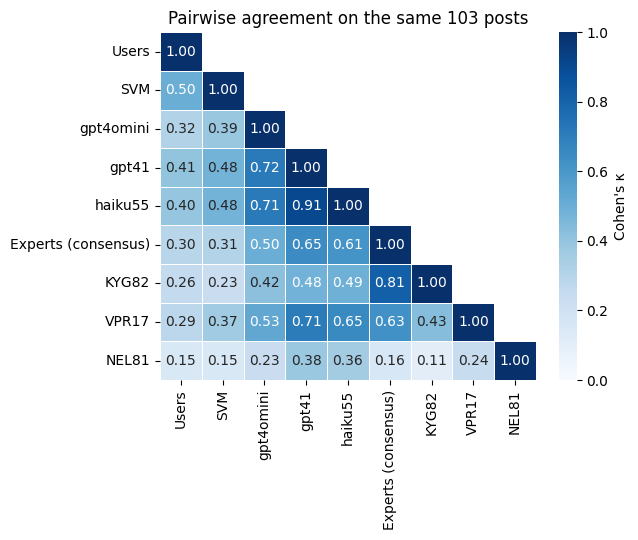


Share of items matching the user label, by user class:
                       svm  gpt4omini  gpt41  haiku55  cons2
user                                                        
Anxiety               0.60       0.87   0.73     0.67   0.73
Bipolar               0.33       0.33   0.42     0.33   0.25
Depression            0.73       0.67   0.67     0.67   0.73
Normal                0.87       0.33   0.67     0.67   0.60
Personality disorder  0.44       0.06   0.19     0.12   0.06
Stress                0.47       0.40   0.33     0.40   0.20
Suicidal              0.53       0.07   0.07     0.20   0.20


In [ ]:
ALL = L.join(LLM).join(SVM)
llm_cols = list(LLM.columns)
SOURCES = ['user', 'svm'] + llm_cols + ['cons2'] + E
ALL.to_csv(out('all_labels.csv'))

tab = pairwise_table(ALL, SOURCES)
tab.to_csv(out('agreement_overall.csv'), index=False)

print('Key contrasts (primary consensus = cons2):')
for a in ['svm'] + llm_cols:
    for b in ['user', 'cons2', 'cons3']:
        print(f'  {a:>10} vs {b:<6} {fmt(agreement(ALL[a], ALL[b]))}')
print(f"  {'user':>10} vs cons2  {fmt(agreement(ALL['user'], ALL['cons2']))}")

# kappa matrix figure
K_ = pd.DataFrame(np.eye(len(SOURCES)), index=SOURCES, columns=SOURCES)
for _, r in tab.iterrows(): K_.loc[r.a, r.b] = K_.loc[r.b, r.a] = r.kappa
nice = {'user': 'Users', 'svm': 'SVM', 'cons2': 'Experts (consensus)'}
K_ = K_.rename(index=nice, columns=nice)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(K_, annot=True, fmt='.2f', vmin=0, vmax=1, cmap='Blues', mask=np.triu(np.ones_like(K_, bool), 1),
            cbar_kws={'label': "Cohen's κ"}, ax=ax, linewidths=.5)
ax.set_title('Pairwise agreement on the same 103 posts')
plt.tight_layout(); plt.savefig(out('fig_agreement.png'), dpi=300); plt.show()

# per-class view: how often each source reproduces the user label
print('\nShare of items matching the user label, by user class:')
print(ALL.groupby('user')[['svm'] + llm_cols + ['cons2']].apply(lambda g: g.eq(ALL.loc[g.index, 'user'], axis=0).mean()).round(2))

### 4b. Confusion matrices: where the disagreements fall

**Input.** `all_labels.csv` (built above).

**What it does.** κ says *how much* two sources agree; a confusion matrix shows *where* they disagree. Three panels, each with the reference source on the rows: (a) expert consensus vs user labels, (b) user labels vs SVM, (c) expert consensus vs the primary LLM (first model in `LLM_MODELS`). Items a source left unlabelled appear in a separate *no label* column. Cells are counts; each panel title gives raw agreement and κ. The expectation: the SVM reproduces the users' confusions (it was trained on them), while the LLM's departures from the experts are few and sit between neighbouring categories.

**Output.** `fig_confusion.png` and `confusion_<pair>.csv` for each panel.

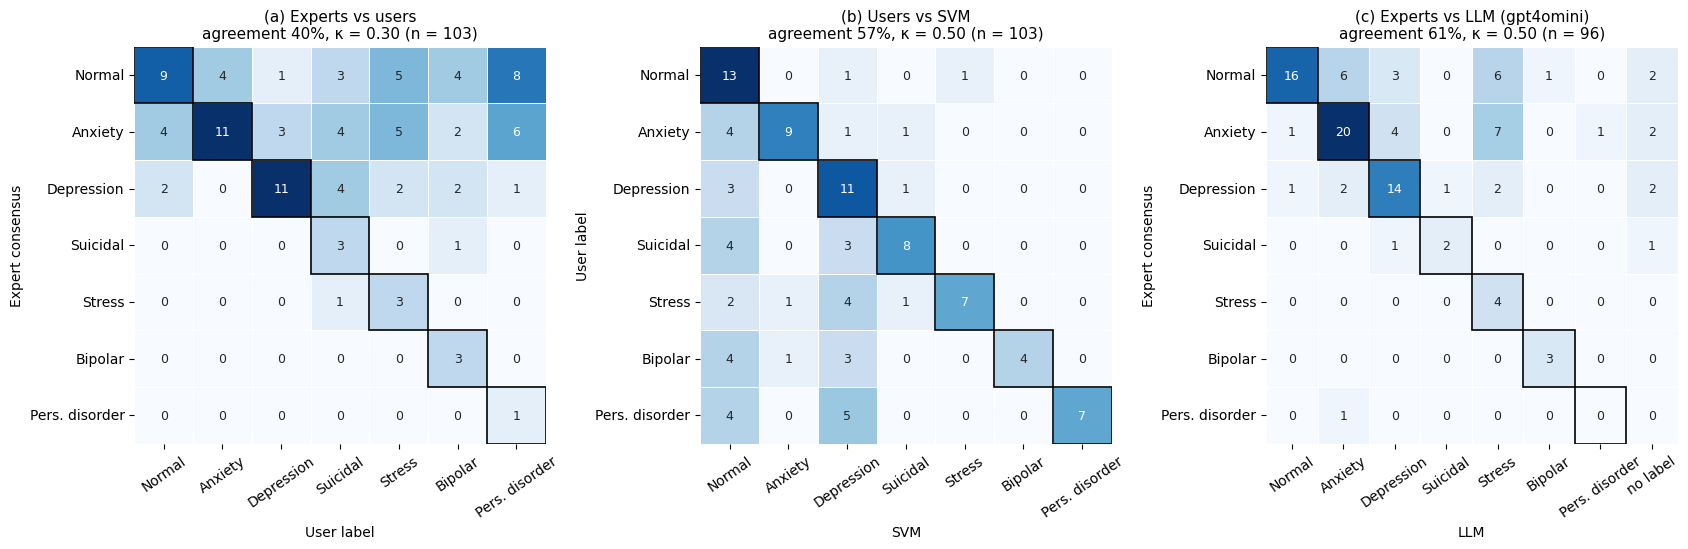

In [ ]:
PRIMARY_LLM = llm_cols[0]
NL = 'no label'
SHORT = {'Personality disorder': 'Pers. disorder'}
PANELS = [('cons2', 'user', '(a) Experts vs users', 'Expert consensus', 'User label'),
          ('user', 'svm', '(b) Users vs SVM', 'User label', 'SVM'),
          ('cons2', PRIMARY_LLM, f'(c) Experts vs LLM ({PRIMARY_LLM})', 'Expert consensus', 'LLM')]

def confusion(ref, other):
    a = ALL[ref].fillna(NL); b = ALL[other].fillna(NL)
    rows = CATS + ([NL] if (a == NL).any() else [])
    cols = CATS + ([NL] if (b == NL).any() else [])
    return pd.crosstab(a, b).reindex(index=rows, columns=cols, fill_value=0)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.6))
for ax, (ref, other, title, ylab, xlab) in zip(axes, PANELS):
    cm = confusion(ref, other)
    cm.to_csv(out(f'confusion_{ref}_vs_{other}.csv'))
    r = agreement(ALL[ref], ALL[other])
    sns.heatmap(cm.rename(index=SHORT, columns=SHORT), annot=True, fmt='d', cmap='Blues', cbar=False,
                linewidths=.5, ax=ax, annot_kws={'size': 9})
    for i, c in enumerate(cm.index):                    # outline the diagonal
        if c in cm.columns:
            ax.add_patch(plt.Rectangle((list(cm.columns).index(c), i), 1, 1, fill=False, ec='black', lw=1.2))
    ax.set_title(f"{title}\nagreement {r['agree']:.0%}, κ = {r['kappa']:.2f} (n = {r['n']})", fontsize=11)
    ax.set_ylabel(ylab); ax.set_xlabel(xlab); ax.tick_params(axis='x', rotation=35); ax.tick_params(axis='y', rotation=0)
plt.tight_layout(); plt.savefig(out('fig_confusion.png'), dpi=300, bbox_inches='tight'); plt.show()

### 4c. Robustness: top-k agreement with the experts

**Input.** The primary experts' score vectors (step 1) and `all_labels.csv`.

**What it does.** Answers the objection that the user label might simply be the experts' second choice. For each post we take the expert consensus score vector (mean of KYG82 and VPR17, as in step 1) and its top-*k* categories (*k* = 1, 2, 3; ties at the cut are included, zero scores never count). For every source, users, SVM and each LLM, we ask the same question: is its single label among the experts' top-*k*? The test is identical for all sources: the LLM is scored on its top-1 label only, since users and the SVM give one label. Because a wider window raises agreement by chance, the expected chance rate (mean set size / 7) is reported alongside.

**Output.** `topk_agreement.csv`.

In [ ]:
stack = np.stack([experts[e].loc[ALL.index, CATS].to_numpy(float) for e in PRIMARY_EXPERTS])
stack = np.where((stack.sum(axis=2) > 0)[..., None], stack, np.nan)
CONS_SCORES = pd.DataFrame(np.nanmean(stack, axis=0), index=ALL.index, columns=CATS).fillna(0)

def top_k_set(row, k):
    s = row[row > 0].sort_values(ascending=False)
    if s.empty: return set()
    return set(s[s >= s.iloc[min(k, len(s)) - 1]].index)

r_ = np.random.default_rng(SEED); rows = []
for k in [1, 2, 3]:
    T = {i: top_k_set(CONS_SCORES.loc[i], k) for i in ALL.index}
    chance = np.mean([len(t) for t in T.values()]) / len(CATS)
    for s in ['user', 'svm'] + llm_cols:
        idx = ALL.index[ALL[s].notna()]
        hit = np.array([ALL.loc[i, s] in T[i] for i in idx], float)
        bs = [hit[r_.integers(0, len(hit), len(hit))].mean() for _ in range(N_BOOT)]
        rows.append(dict(k=k, source=s, n=len(hit), in_topk=hit.mean(),
                         lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5), chance=chance))
topk = pd.DataFrame(rows); topk.to_csv(out('topk_agreement.csv'), index=False)
print(topk.pivot(index='source', columns='k', values='in_topk').round(2))
print('chance by k:', topk.groupby('k').chance.first().round(2).to_dict())

k             1     2     3
source                     
gpt41      0.74  0.93  0.96
gpt4omini  0.61  0.85  0.93
haiku55    0.71  0.92  0.97
svm        0.46  0.71  0.78
user       0.40  0.57  0.67
chance by k: {1: 0.14, 2: 0.27, 3: 0.39}


### 4d. Sensitivity: reliability and three-rater consensus

**Input.** `all_labels.csv` (built above).

**What it does.** (a) Computes Krippendorff's α (nominal) for all three experts, for the primary pair, and for the primary pair with each other source (users, SVM, each LLM) added as a third rater: a source that reads posts like an expert should raise α, one that does not should lower it. (b) Repeats the key agreement contrasts against `cons3`, the consensus of all three experts built as in step 1 (a rater who left a post unscored is omitted from that post's mean).

**Output.** `reliability_alpha.csv` and `agreement_cons3.csv`.


In [ ]:
# (a) Reliability: Krippendorff's alpha of the experts, and of the primary pair with each other source added as a third rater
rows = [dict(raters=' + '.join(E), alpha=kripp_alpha(ALL[E])),
        dict(raters=' + '.join(PRIMARY_EXPERTS), alpha=kripp_alpha(ALL[PRIMARY_EXPERTS]))]
for s in ['user', 'svm'] + llm_cols:
    rows.append(dict(raters=' + '.join(PRIMARY_EXPERTS + [s]), alpha=kripp_alpha(ALL[PRIMARY_EXPERTS + [s]])))
rel = pd.DataFrame(rows); rel.to_csv(out('reliability_alpha.csv'), index=False)
print(rel.round(2).to_string(index=False), '\n')

# (b) Agreement with the three-rater consensus (cons3, built as in step 1)
c3 = pd.DataFrame([dict(source=s, **agreement(ALL[s], ALL['cons3'])) for s in ['user', 'svm'] + llm_cols])
c3.to_csv(out('agreement_cons3.csv'), index=False)
for _, r in c3.iterrows(): print(f'{r.source:>10} vs cons3  {fmt(r)}')


## 5. Stratification by text length

**Input.** `all_labels.csv` and the `size` column (the expert sample was drawn from the bottom 10%, middle 10% and top 10% of word counts within each class, so *short* texts are typically under ten words).

**What it does.** Repeats the key contrasts of step 4 separately for short, mid and long texts. Hypothesis: longer texts carry more evidence, so agreement among content readers (experts, LLM) should rise with length, while their agreement with the user label need not. With about 34 texts per stratum the intervals are wide; treat this as exploratory.

**Output.** `agreement_by_length.csv` and `fig_length.png`.

size                short   mid  long
pair                                 
KYG82 vs VPR17       0.73  0.53  0.45
gpt41 vs cons2       0.85  0.68  0.67
gpt41 vs user        0.39  0.48  0.63
gpt4omini vs cons2   0.61  0.59  0.65
gpt4omini vs user    0.39  0.38  0.48
haiku55 vs cons2     0.84  0.62  0.66
haiku55 vs user      0.41  0.44  0.62
svm vs cons2         0.52  0.43  0.43
svm vs user          0.70  0.49  0.54
user vs cons2        0.33  0.46  0.40

n per cell:
size                short  mid  long
pair                                
KYG82 vs VPR17         30   30    31
gpt41 vs cons2         33   31    27
gpt41 vs user          33   31    27
gpt4omini vs cons2     31   34    31
gpt4omini vs user      31   34    31
haiku55 vs cons2       32   32    29
haiku55 vs user        32   32    29
svm vs cons2           33   35    35
svm vs user            33   35    35
user vs cons2          33   35    35


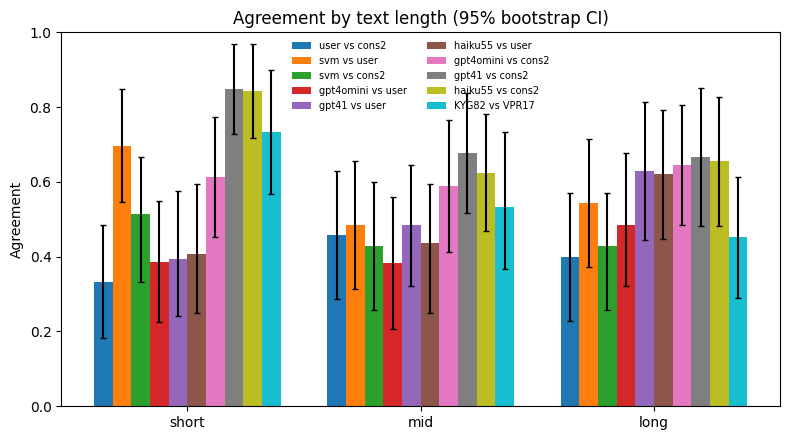

In [ ]:
PAIRS = [('user', 'cons2'), ('svm', 'user'), ('svm', 'cons2')] + \
        [(m, 'user') for m in llm_cols] + [(m, 'cons2') for m in llm_cols] + [tuple(PRIMARY_EXPERTS)]
rows = []
for size in SIZES:
    sub = ALL[ALL['size'] == size]
    for a, b in PAIRS:
        rows.append(dict(size=size, pair=f'{a} vs {b}', **agreement(sub[a], sub[b])))
byL = pd.DataFrame(rows)
byL.to_csv(out('agreement_by_length.csv'), index=False)
print(byL.pivot(index='pair', columns='size', values='agree')[SIZES].round(2))
print('\nn per cell:'); print(byL.pivot(index='pair', columns='size', values='n')[SIZES])

fig, ax = plt.subplots(figsize=(8, 4.5))
pairs = byL.pair.unique(); w = 0.8 / len(pairs); x = np.arange(len(SIZES))
for i, p in enumerate(pairs):
    d = byL[byL.pair == p].set_index('size').loc[SIZES]
    ax.bar(x + i * w, d.agree, w, yerr=[d.agree - d.agree_lo, d.agree_hi - d.agree], capsize=2, label=p)
ax.set_xticks(x + w * (len(pairs) - 1) / 2); ax.set_xticklabels(SIZES)
ax.set_ylabel('Agreement'); ax.set_ylim(0, 1); ax.legend(fontsize=7, ncol=2, frameon=False)
ax.set_title('Agreement by text length (95% bootstrap CI)')
plt.tight_layout(); plt.savefig(out('fig_length.png'), dpi=300); plt.show()

## 6. Shortcut check: a classifier that never reads the words

**Input.** The Kaggle data.

**What it does.** Trains a gradient-boosting classifier on eleven style features only: word and character counts, line breaks, upper-case and punctuation ratios, apostrophes, URLs, digits, a capitalised first letter, question and exclamation marks. Same stratified 80/20 split as step 3. If style alone predicts the label far above the majority baseline, the labels encode *where a post came from* (subreddit or Twitter corpus and its preprocessing) at least as much as what it says. The per-class style table shows where that signal comes from.

**Output.** `shortcut.txt` and `style_by_class.csv`.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

def style_features(s):
    s = s.astype(str); n = s.str.len().clip(lower=1)
    return pd.DataFrame({
        'words': s.str.split().str.len(), 'chars': s.str.len(), 'newlines': s.str.count('\n'),
        'upper_ratio': s.str.count(r'[A-Z]') / n, 'punct_ratio': s.str.count(r'[^\w\s]') / n,
        'apostrophes': s.str.count(r"['’]"), 'url': s.str.contains(r'http|www').astype(int),
        'digits': s.str.count(r'\d'), 'first_upper': s.str[:1].str.isupper().astype(int),
        'questions': s.str.count(r'\?'), 'exclamations': s.str.count('!')})

X, y = style_features(K.statement), K.status
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
acc = accuracy_score(yte, HistGradientBoostingClassifier(random_state=SEED).fit(Xtr, ytr).predict(Xte))
base_rate = y.value_counts(normalize=True).max()
msg = f'style-only accuracy: {acc:.3f}   majority-class baseline: {base_rate:.3f}   paper zero-shot LLM: 0.65   paper SVM: 0.95'
open(out('shortcut.txt'), 'w').write(msg); print(msg)

style = K.assign(words=X.words, has_newline=X.newlines > 0, has_apostrophe=X.apostrophes > 0,
                 all_lowercase=K.statement == K.statement.str.lower())
tbl = style.groupby('status').agg(n=('words', 'size'), median_words=('words', 'median'),
        has_newline=('has_newline', 'mean'), has_apostrophe=('has_apostrophe', 'mean'),
        all_lowercase=('all_lowercase', 'mean')).round(2)
tbl.to_csv(out('style_by_class.csv')); tbl

style-only accuracy: 0.623   majority-class baseline: 0.310   paper zero-shot LLM: 0.65   paper SVM: 0.95


,n,median_words,has_newline,has_apostrophe,all_lowercase
status,,,,,
Anxiety,3841,102.0,0.48,0.82,0.05
Bipolar,2777,129.0,0.63,0.90,0.02
Depression,15404,113.0,0.04,0.13,0.26
Normal,16343,10.0,0.00,0.30,0.56
Personality disorder,1077,137.0,0.69,0.87,0.04
Stress,2587,87.0,0.25,0.81,0.02
Suicidal,10652,92.0,0.00,0.09,0.04
